In [1]:
# ──  Dependencies ──────────────────────────────────────────────────────────
import subprocess, sys
def _install(pkg):
    subprocess.check_call([sys.executable,'-m','pip','install','-q',pkg])
for pkg in ['rdkit','xgboost','imbalanced-learn','scikit-learn',
            'matplotlib','seaborn','openpyxl','torch','torch-geometric']:
    try: __import__(pkg.replace('-','_'))
    except ImportError: _install(pkg)
print('Dependencies OK.')

Dependencies OK.


In [2]:
# ── Imports ────────────────────────────────────────────────────────────────
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import copy, time

from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import (
    roc_auc_score, average_precision_score, matthews_corrcoef,
    balanced_accuracy_score, f1_score, confusion_matrix,
    roc_curve, precision_recall_curve, classification_report
)
from xgboost import XGBClassifier

import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import GCNConv, GATConv, GINConv, SAGEConv, global_mean_pool
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cpu


---
## Step 1 — Data Loading, Curation & Label Assignment

In [3]:
# ──  Load Caspase HepG2 Data ────────────────────────────────────────────────
df_raw = pd.read_csv('combined_hepg2_casepase.csv',
    usecols=['PUBCHEM_CID','PUBCHEM_EXT_DATASOURCE_SMILES',
             'PUBCHEM_ACTIVITY_SCORE','PUBCHEM_ACTIVITY_OUTCOME'])
print(f'Raw rows : {len(df_raw):,}')
print(df_raw['PUBCHEM_ACTIVITY_OUTCOME'].value_counts())
print(df_raw['PUBCHEM_ACTIVITY_SCORE'].describe())

Raw rows : 7,716
PUBCHEM_ACTIVITY_OUTCOME
Inactive        7172
Inconclusive     303
Active           241
Name: count, dtype: int64
count    7716.000000
mean        2.222136
std        10.344257
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       100.000000
Name: PUBCHEM_ACTIVITY_SCORE, dtype: float64


In [4]:
# ──  SMILES + deduplication ────────────────────────────────────────────────
def canonicalize(smi):
    try:
        mol = Chem.MolFromSmiles(str(smi))
        return Chem.MolToSmiles(mol) if mol else None
    except: return None

df_raw['csmi'] = df_raw['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(canonicalize)
df = df_raw.dropna(subset=['csmi'])
print(f'After parse : {len(df):,}  (removed {len(df_raw)-len(df)} invalid SMILES)')
df = df.drop_duplicates('csmi', keep='first').reset_index(drop=True)
print(f'After dedup : {len(df):,}')

[18:56:50] WARNING: not removing hydrogen atom without neighbors


After parse : 7,716  (removed 0 invalid SMILES)
After dedup : 7,714


Removed 294 inconclusive
Active   (1): 249
Inactive (0): 7,171
Ratio       : 28.8:1


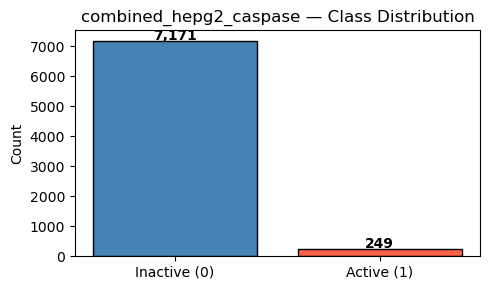

In [5]:
# ── Binary Labels
#  Active (score >= 40) -> 1 | Inactive (score = 0) -> 0 | Inconclusive -> drop
df['label'] = df['PUBCHEM_ACTIVITY_SCORE'].apply(
    lambda s: 1 if s>=40 else (0 if s==0 else np.nan))
n_inc = df['label'].isna().sum()
df = df.dropna(subset=['label']).copy()
df['label'] = df['label'].astype(int)

n_act, n_ina = (df['label']==1).sum(), (df['label']==0).sum()
print(f'Removed {n_inc:,} inconclusive')
print(f'Active   (1): {n_act:,}')
print(f'Inactive (0): {n_ina:,}')
print(f'Ratio       : {n_ina/n_act:.1f}:1')

fig, ax = plt.subplots(figsize=(5,3))
bars = ax.bar(['Inactive (0)','Active (1)'],[n_ina,n_act],
              color=['steelblue','tomato'], edgecolor='black')
for b,v in zip(bars,[n_ina,n_act]):
    ax.text(b.get_x()+b.get_width()/2, v+30, f'{v:,}', ha='center', fontweight='bold')
ax.set_title('combined_hepg2_caspase — Class Distribution')
ax.set_ylabel('Count')
plt.tight_layout(); plt.savefig('caspase_class_dist.png',dpi=150); plt.show()

---
## Step 2 — Feature Engineering

### 2A. Morgan Fingerprints (ECFP4) — for Classical ML
### 2B. Rich Atom/Bond Graph Features — for GNN

In [6]:
# ── Morgan ECFP4 (2048 bits) ─────────────────────────────────────────────
def smiles_to_ecfp4(smi, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    fp  = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)
    arr = np.zeros(n_bits, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

fps = df['csmi'].apply(smiles_to_ecfp4)
valid = fps.notna()
df    = df[valid].reset_index(drop=True)
fps   = fps[valid]
X_fp  = np.vstack(fps.values)   # (N, 2048)
y_all = df['label'].values
print(f'Fingerprint matrix : {X_fp.shape}')
print(f'FP density         : {X_fp.mean():.4f}')

[18:56:50] DEPRECATION WARNING: please use MorganGenerator
[18:56:50] DEPRECATION WARNING: please use MorganGenerator
[18:56:50] DEPRECATION WARNING: please use MorganGenerator
[18:56:50] DEPRECATION WARNING: please use MorganGenerator
[18:56:50] DEPRECATION WARNING: please use MorganGenerator
[18:56:50] DEPRECATION WARNING: please use MorganGenerator
[18:56:50] DEPRECATION WARNING: please use MorganGenerator
[18:56:50] DEPRECATION WARNING: please use MorganGenerator
[18:56:50] DEPRECATION WARNING: please use MorganGenerator
[18:56:50] DEPRECATION WARNING: please use MorganGenerator
[18:56:50] DEPRECATION WARNING: please use MorganGenerator
[18:56:50] DEPRECATION WARNING: please use MorganGenerator
[18:56:50] DEPRECATION WARNING: please use MorganGenerator
[18:56:50] DEPRECATION WARNING: please use MorganGenerator
[18:56:50] DEPRECATION WARNING: please use MorganGenerator
[18:56:50] DEPRECATION WARNING: please use MorganGenerator
[18:56:50] DEPRECATION WARNING: please use MorganGenerat

Fingerprint matrix : (7420, 2048)
FP density         : 0.0135


[18:56:51] DEPRECATION WARNING: please use MorganGenerator
[18:56:51] DEPRECATION WARNING: please use MorganGenerator
[18:56:51] DEPRECATION WARNING: please use MorganGenerator
[18:56:51] DEPRECATION WARNING: please use MorganGenerator
[18:56:51] DEPRECATION WARNING: please use MorganGenerator
[18:56:51] DEPRECATION WARNING: please use MorganGenerator
[18:56:51] DEPRECATION WARNING: please use MorganGenerator
[18:56:51] DEPRECATION WARNING: please use MorganGenerator
[18:56:51] DEPRECATION WARNING: please use MorganGenerator
[18:56:51] DEPRECATION WARNING: please use MorganGenerator
[18:56:51] DEPRECATION WARNING: please use MorganGenerator
[18:56:51] DEPRECATION WARNING: please use MorganGenerator
[18:56:51] DEPRECATION WARNING: please use MorganGenerator
[18:56:51] DEPRECATION WARNING: please use MorganGenerator
[18:56:51] DEPRECATION WARNING: please use MorganGenerator
[18:56:51] DEPRECATION WARNING: please use MorganGenerator
[18:56:51] DEPRECATION WARNING: please use MorganGenerat

In [7]:
# ──  Rich Atom Features (27-dim) & Bond Features (6-dim) — for GNN ──────────
ATOM_SYMBOLS = [6,7,8,16,9,15,17,35,53]  # C N O S F P Cl Br I

def one_hot(val, choices):
    vec = [0]*len(choices)
    try: vec[choices.index(val)] = 1
    except ValueError: pass
    return vec

from rdkit.Chem import rdchem
HYBRID_MAP = {
    rdchem.HybridizationType.SP  : 0,
    rdchem.HybridizationType.SP2 : 1,
    rdchem.HybridizationType.SP3 : 2,
}

def atom_feat(atom):
    at_oh  = one_hot(atom.GetAtomicNum(), ATOM_SYMBOLS) + [0]  # 10-dim (+other)
    hyb    = [0,0,0,0]
    hyb[HYBRID_MAP.get(atom.GetHybridization(), 3)] = 1
    deg    = min(atom.GetDegree(), 5)
    deg_oh = [0]*6; deg_oh[deg]=1
    fc     = atom.GetFormalCharge()
    fc_enc = [1 if fc<0 else 0, 1 if fc==0 else 0, 1 if fc>0 else 0]
    extras = [
        int(atom.GetIsAromatic()),
        int(atom.IsInRing()),
        min(atom.GetTotalNumHs(), 4) / 4.0,
        atom.GetMass() / 100.0
    ]
    return at_oh + deg_oh + fc_enc + hyb + extras  # 10+6+3+4+4 = 27-dim

BOND_TYPES = [
    rdchem.BondType.SINGLE,
    rdchem.BondType.DOUBLE,
    rdchem.BondType.TRIPLE,
    rdchem.BondType.AROMATIC
]

def bond_feat(bond):
    bt = one_hot(bond.GetBondType(), BOND_TYPES)  # 4-dim
    return bt + [int(bond.GetIsConjugated()), int(bond.IsInRing())]  # 6-dim

from rdkit.Chem import MolFromSmiles
_mol = MolFromSmiles('CC(=O)O')
ATOM_DIM = len(atom_feat(_mol.GetAtomWithIdx(0)))
BOND_DIM  = len(bond_feat(_mol.GetBondWithIdx(0)))
print(f'Atom feature dim : {ATOM_DIM}')
print(f'Bond feature dim : {BOND_DIM}')

Atom feature dim : 27
Bond feature dim : 6


In [8]:
# ── Build Graph Dataset ──────────────────────────────────────────────────────
def mol_to_graph(smi, label):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    x = torch.tensor([atom_feat(a) for a in mol.GetAtoms()], dtype=torch.float)
    ei, ea = [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bf = bond_feat(bond)
        ei += [[i,j],[j,i]]
        ea += [bf, bf]
    if ei:
        edge_index = torch.tensor(ei, dtype=torch.long).t().contiguous()
        edge_attr  = torch.tensor(ea, dtype=torch.float)
    else:
        edge_index = torch.zeros((2,0), dtype=torch.long)
        edge_attr  = torch.zeros((0, BOND_DIM), dtype=torch.float)
    y = torch.tensor([label], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y)

graph_list = []
for smi, lbl in zip(df['csmi'].values, y_all):
    g = mol_to_graph(smi, lbl)
    if g: graph_list.append(g)

print(f'Graphs built: {len(graph_list):,}')
print(f'Example: {graph_list[0]}')

[18:56:52] WARNING: not removing hydrogen atom without neighbors


Graphs built: 7,420
Example: Data(x=[5, 27], edge_index=[2, 8], edge_attr=[8, 6], y=[1])


---
## Step 3 — 80/20/20 Split + Downsampling

- **20%** held-out internal test (caspase) — stratified
- **80% pool → 80/20** train-raw / val
- Downsampling **only on train** to 1:1; val & test keep real-world imbalance

In [9]:
# ── 20% External Test Split ──────────────────────────────────────────────────
idx_all = np.arange(len(y_all))
idx_pool, idx_test = train_test_split(
    idx_all, test_size=0.20, stratify=y_all, random_state=SEED)

X_pool,  X_test  = X_fp[idx_pool],  X_fp[idx_test]
y_pool,  y_test  = y_all[idx_pool],  y_all[idx_test]
graphs_pool = [graph_list[i] for i in idx_pool]
graphs_test = [graph_list[i] for i in idx_test]

print(f'Pool : {len(y_pool):,}  (act={(y_pool==1).sum()}, ina={(y_pool==0).sum()})')
print(f'Test : {len(y_test):,}  (act={(y_test==1).sum()}, ina={(y_test==0).sum()})')

Pool : 5,936  (act=199, ina=5737)
Test : 1,484  (act=50, ina=1434)


In [10]:
# ── 80/20 Train/Val Split from Pool ────────────────────────────────────────
pool_sub_idx = np.arange(len(y_pool))
tr_sub_idx, val_sub_idx = train_test_split(
    pool_sub_idx, test_size=0.20, stratify=y_pool, random_state=SEED)

X_tr_raw, X_val = X_pool[tr_sub_idx], X_pool[val_sub_idx]
y_tr_raw, y_val = y_pool[tr_sub_idx], y_pool[val_sub_idx]
graphs_val    = [graphs_pool[i] for i in val_sub_idx]
graphs_trraw  = [graphs_pool[i] for i in tr_sub_idx]

print(f'Train-raw: {len(y_tr_raw):,}  (act={(y_tr_raw==1).sum()}, ina={(y_tr_raw==0).sum()})')
print(f'Val      : {len(y_val):,}  (act={(y_val==1).sum()},  ina={(y_val==0).sum()})')

Train-raw: 4,748  (act=159, ina=4589)
Val      : 1,188  (act=40,  ina=1148)


In [11]:
# ──  Downsampling on TRAIN ONLY (1:1) ────────────────────────────────────────
act_idx_tr  = np.where(y_tr_raw == 1)[0]
ina_idx_tr  = np.where(y_tr_raw == 0)[0]
n_act_tr    = len(act_idx_tr)

rng = np.random.RandomState(SEED)
sampled_ina = rng.choice(ina_idx_tr, size=n_act_tr, replace=False)

train_idx   = np.concatenate([act_idx_tr, sampled_ina])
rng.shuffle(train_idx)

X_train = X_tr_raw[train_idx]
y_train = y_tr_raw[train_idx]
graphs_train = [graphs_trraw[i] for i in train_idx]

print(f'Balanced TRAIN: {len(y_train):,}  act={(y_train==1).sum()} / ina={(y_train==0).sum()} (1:1)')
print(f'VAL  (real-world imbalance): {len(y_val):,}  ratio={(y_val==0).sum()/(y_val==1).sum():.1f}:1')
print(f'TEST (real-world imbalance): {len(y_test):,}  ratio={(y_test==0).sum()/(y_test==1).sum():.1f}:1')

Balanced TRAIN: 318  act=159 / ina=159 (1:1)
VAL  (real-world imbalance): 1,188  ratio=28.7:1
TEST (real-world imbalance): 1,484  ratio=28.7:1


Split summary (% of total)
  Train:   318 (4.3%)  act=159, ina=159
  Val  : 1,188 (16.0%)  act=40, ina=1148
  Test : 1,484 (20.0%)  act=50, ina=1434


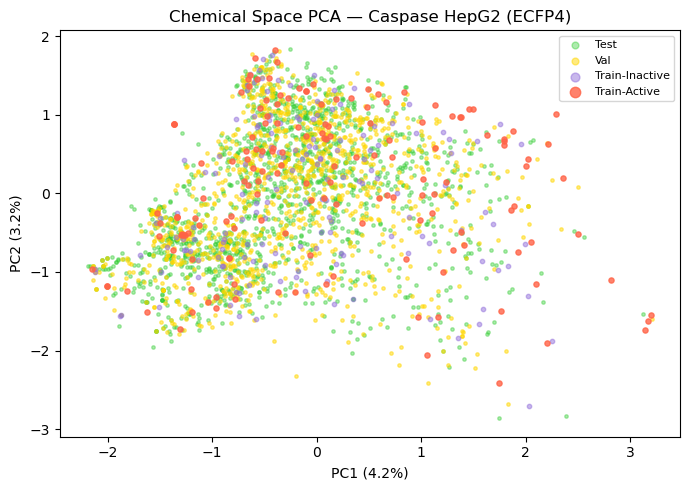

In [12]:
# ── Split Summary & Chemical Space PCA ──────────────────────────────────────
print('Split summary (% of total)')
for name, ys in [('Train',y_train),('Val',y_val),('Test',y_test)]:
    print(f'  {name:5s}: {len(ys):5,} ({100*len(ys)/len(y_all):.1f}%)  '
          f'act={(ys==1).sum()}, ina={(ys==0).sum()}')

pca = PCA(n_components=2, random_state=SEED)
pca.fit(X_train)
tr_p, va_p, te_p = pca.transform(X_train), pca.transform(X_val), pca.transform(X_test)

fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(te_p[:,0], te_p[:,1], c='limegreen', s=6, alpha=0.4, label='Test')
ax.scatter(va_p[:,0], va_p[:,1], c='gold',      s=6, alpha=0.5, label='Val')
ax.scatter(tr_p[y_train==0,0], tr_p[y_train==0,1], c='mediumpurple', s=10, alpha=0.5, label='Train-Inactive')
ax.scatter(tr_p[y_train==1,0], tr_p[y_train==1,1], c='tomato',       s=14, alpha=0.8, label='Train-Active')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title('Chemical Space PCA — Caspase HepG2 (ECFP4)')
ax.legend(markerscale=2, fontsize=8); plt.tight_layout()
plt.savefig('caspase_chem_space.png',dpi=150); plt.show()

---
## Step 4 — Evaluation Helpers

In [13]:
# ── Metrics Helper ────────────────────────────────────────────────────────────
def evaluate(y_true, y_prob, name, cpt=0.5):
    y_pred = (y_prob >= cpt).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_true, y_pred).ravel()
    sens = tp/(tp+fn) if (tp+fn)>0 else 0
    spec = tn/(tn+fp) if (tn+fp)>0 else 0
    return {
        'Model'      : name,
        'CPT'        : cpt,
        'Sensitivity': round(sens*100,1),
        'Specificity': round(spec*100,1),
        'CCR'        : round((sens+spec)/2*100,1),
        'ROC-AUC'    : round(roc_auc_score(y_true, y_prob),4),
        'PR-AUC'     : round(average_precision_score(y_true, y_prob),4),
        'MCC'        : round(matthews_corrcoef(y_true, y_pred),4),
        'Bal-Acc'    : round(balanced_accuracy_score(y_true,y_pred)*100,1),
        'F1'         : round(f1_score(y_true,y_pred,zero_division=0),4),
        'TP':tp,'TN':tn,'FP':fp,'FN':fn
    }

METRIC_COLS = ['Model','CPT','Sensitivity','Specificity','CCR',
               'ROC-AUC','PR-AUC','MCC','Bal-Acc','F1']
print('Helpers ready.')

Helpers ready.


---
## Step 5 — Classical ML: Hyperparameter Tuning on Validation Set

Train on balanced training set → tune on (imbalanced) validation set by **ROC-AUC** → final eval on test.

In [14]:
# ── Random Forest Grid Search ────────────────────────────────────────────────
rf_grid = ParameterGrid({
    'n_estimators'  : [300, 500],
    'max_features'  : ['sqrt', 0.3],
    'min_samples_leaf': [1, 3],
    'max_depth'     : [None, 20]
})

best_rf_auc, best_rf, best_rf_params = 0, None, {}
print(f'RF: {len(rf_grid)} configs...')
for p in rf_grid:
    clf = RandomForestClassifier(**p, class_weight='balanced', n_jobs=-1, random_state=SEED)
    clf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])
    if auc > best_rf_auc:
        best_rf_auc, best_rf, best_rf_params = auc, clf, p

print(f'Best RF  val AUC={best_rf_auc:.4f}  params={best_rf_params}')

RF: 16 configs...
Best RF  val AUC=0.8023  params={'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}


In [15]:
# ── SVM Grid Search ───────────────────────────────────────────────────────────
svm_grid = ParameterGrid({
    'C'    : [1, 10, 50],
    'gamma': ['scale', 0.01, 0.001]
})

best_svm_auc, best_svm, best_svm_params = 0, None, {}
print(f'SVM: {len(svm_grid)} configs...')
for p in svm_grid:
    clf = SVC(**p, kernel='rbf', class_weight='balanced', probability=True, random_state=SEED)
    clf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])
    if auc > best_svm_auc:
        best_svm_auc, best_svm, best_svm_params = auc, clf, p

print(f'Best SVM val AUC={best_svm_auc:.4f}  params={best_svm_params}')

SVM: 9 configs...
Best SVM val AUC=0.8268  params={'C': 1, 'gamma': 'scale'}


In [16]:
# ── XGBoost Grid Search ──────────────────────────────────────────────────────
sw = (y_train==0).sum() / (y_train==1).sum()
xgb_grid = ParameterGrid({
    'n_estimators' : [300, 500],
    'max_depth'    : [4, 6, 8],
    'learning_rate': [0.05, 0.1],
    'subsample'    : [0.8],
    'colsample_bytree': [0.8]
})

best_xgb_auc, best_xgb, best_xgb_params = 0, None, {}
print(f'XGB: {len(xgb_grid)} configs...')
for p in xgb_grid:
    clf = XGBClassifier(**p, scale_pos_weight=sw, eval_metric='logloss',
                        n_jobs=-1, random_state=SEED, verbosity=0)
    clf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])
    if auc > best_xgb_auc:
        best_xgb_auc, best_xgb, best_xgb_params = auc, clf, p

print(f'Best XGB val AUC={best_xgb_auc:.4f}  params={best_xgb_params}')

XGB: 12 configs...
Best XGB val AUC=0.7329  params={'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 8, 'n_estimators': 300, 'subsample': 0.8}


In [17]:
# ── Classical ML — Val & Test Evaluation ─────────────────────────────────────
classical = {'Random Forest': best_rf, 'SVM': best_svm, 'XGBoost': best_xgb}
cl_probs_val  = {n: clf.predict_proba(X_val)[:,1]  for n,clf in classical.items()}
cl_probs_test = {n: clf.predict_proba(X_test)[:,1] for n,clf in classical.items()}

rows_val, rows_test = [], []
for name in classical:
    for cpt in [0.5, 0.8]:
        rows_val.append(evaluate(y_val,  cl_probs_val[name],  name, cpt))
        rows_test.append(evaluate(y_test, cl_probs_test[name], name, cpt))

df_cl_val  = pd.DataFrame(rows_val)[METRIC_COLS]
df_cl_test = pd.DataFrame(rows_test)[METRIC_COLS]

print('── Classical ML — Validation Set ──')
display(df_cl_val.set_index(['Model','CPT']))
print('\n── Classical ML — Internal Test Set ──')
display(df_cl_test.set_index(['Model','CPT']))

── Classical ML — Validation Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  \
Model         CPT                                                            
Random Forest 0.5         67.5         76.2  71.9   0.8023  0.2986  0.1815   
              0.8         15.0         99.8  57.4   0.8023  0.2986  0.3270   
SVM           0.5         85.0         68.6  76.8   0.8268  0.2815  0.2050   
              0.8         10.0        100.0  55.0   0.8268  0.2815  0.3114   
XGBoost       0.5         62.5         65.4  64.0   0.7329  0.1848  0.1052   
              0.8         40.0         90.4  65.2   0.7329  0.1848  0.1782   

                   Bal-Acc      F1  
Model         CPT                   
Random Forest 0.5     71.9  0.1588  
              0.8     57.4  0.2500  
SVM           0.5     76.8  0.1563  
              0.8     55.0  0.1818  
XGBoost       0.5     64.0  0.1082  
              0.8     65.2  0.1928


── Classical ML — Internal Test Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  \
Model         CPT                                                            
Random Forest 0.5         56.0         78.6  67.3   0.7956  0.1682  0.1493   
              0.8          8.0         99.3  53.7   0.7956  0.1682  0.1363   
SVM           0.5         72.0         68.1  70.0   0.7769  0.1679  0.1534   
              0.8          6.0         99.9  52.9   0.7769  0.1679  0.1825   
XGBoost       0.5         60.0         63.5  61.7   0.6946  0.0941  0.0875   
              0.8         32.0         89.4  60.7   0.6946  0.0941  0.1219   

                   Bal-Acc      F1  
Model         CPT                   
Random Forest 0.5     67.3  0.1455  
              0.8     53.7  0.1250  
SVM           0.5     70.0  0.1324  
              0.8     52.9  0.1091  
XGBoost       0.5     61.7  0.0993  
              0.8     60.7  0.1468

---
## Step 6 — Graph Neural Networks (Classification)

**Architecture** (same for all 4 variants):
```
SMILES → Atoms+Bonds (27-dim / 6-dim)
  - Linear projection (hidden)
  - 3 × [Conv + BatchNorm1d + ReLU + Dropout + Residual]
  - GlobalMeanPool
  - MLP head [hidden→hidden/2→1]
  - BCEWithLogitsLoss
```
Selection criterion: **val ROC-AUC** | Early stopping patience=20 epochs

In [18]:
# ── GNN Architecture ─────────────────────────────────────────────────────────
class MolGNN(nn.Module):
    """GNN for molecular binary classification with residual connections."""

    def __init__(self, in_dim, hidden=128, n_layers=3, dropout=0.3,
                 conv_type='GCN', heads=4):
        super().__init__()
        self.conv_type = conv_type
        self.n_layers  = n_layers
        self.drop      = nn.Dropout(dropout)

        self.proj = nn.Linear(in_dim, hidden)
        self.bn0  = nn.BatchNorm1d(hidden)

        self.convs = nn.ModuleList()
        self.bns   = nn.ModuleList()
        for _ in range(n_layers):
            if conv_type == 'GCN':
                self.convs.append(GCNConv(hidden, hidden))
            elif conv_type == 'GAT':
                self.convs.append(GATConv(hidden, hidden, heads=heads,
                                          concat=False, dropout=dropout))
            elif conv_type == 'GIN':
                mlp = nn.Sequential(
                    nn.Linear(hidden, hidden*2),
                    nn.BatchNorm1d(hidden*2),
                    nn.ReLU(),
                    nn.Linear(hidden*2, hidden))
                self.convs.append(GINConv(mlp, train_eps=True))
            elif conv_type == 'SAGE':
                self.convs.append(SAGEConv(hidden, hidden))
            self.bns.append(nn.BatchNorm1d(hidden))

        self.head = nn.Sequential(
            nn.Linear(hidden, hidden//2), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden//2, 1))

    def forward(self, x, edge_index, batch):
        x = F.relu(self.bn0(self.proj(x)))
        x = self.drop(x)
        for conv, bn in zip(self.convs, self.bns):
            x_res = x
            x = conv(x, edge_index)
            x = bn(x)
            x = F.relu(x)
            x = self.drop(x)
            x = x + x_res          # residual connection
        x = global_mean_pool(x, batch)
        return self.head(x).squeeze(-1)

print(f'MolGNN defined. ATOM_DIM={ATOM_DIM}')

MolGNN defined. ATOM_DIM=27


In [19]:
# ── Training & Evaluation Functions ──────────────────────────────────────────
def gnn_train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        logits = model(batch.x, batch.edge_index, batch.batch)
        loss   = criterion(logits, batch.y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch.num_graphs
    return total_loss / len(loader.dataset)

@torch.no_grad()
def gnn_eval(model, loader, device):
    model.eval()
    all_logits, all_labels = [], []
    for batch in loader:
        batch = batch.to(device)
        all_logits.append(model(batch.x, batch.edge_index, batch.batch).cpu())
        all_labels.append(batch.y.cpu())
    logits = torch.cat(all_logits).numpy()
    labels = torch.cat(all_labels).numpy().astype(int)
    probs  = torch.sigmoid(torch.tensor(logits)).numpy()
    auc    = roc_auc_score(labels, probs)
    return probs, labels, auc

print('Training helpers defined.')

Training helpers defined.


In [20]:
# ── GNN DataLoaders ──────────────────────────────────────────────────────────
BATCH = 64
train_loader = DataLoader(graphs_train, batch_size=BATCH, shuffle=True)
val_loader   = DataLoader(graphs_val,   batch_size=BATCH, shuffle=False)
test_loader  = DataLoader(graphs_test,  batch_size=BATCH, shuffle=False)

pos_weight = torch.tensor([(y_train==0).sum()/(y_train==1).sum()], device=DEVICE)
criterion  = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

print(f'Train graphs : {len(graphs_train)}')
print(f'Val   graphs : {len(graphs_val)}')
print(f'Test  graphs : {len(graphs_test)}')
print(f'pos_weight   : {pos_weight.item():.3f} (1.0 = balanced)')

Train graphs : 318
Val   graphs : 1188
Test  graphs : 1484
pos_weight   : 1.000 (1.0 = balanced)


In [21]:
# ── Hyperparameter Grid & Training Loop ──────────────────────────────────────
GNN_CONFIGS = {
    'GCN' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
    'GAT' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001,  'heads':4},
        {'hidden':128, 'n_layers':3, 'dropout':0.4, 'lr':0.0005, 'heads':8},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001,  'heads':4},
    ],
    'GIN' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
    'SAGE': [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
}

MAX_EPOCHS = 100
PATIENCE   = 20

gnn_best_models  = {}
gnn_best_configs = {}
gnn_best_val_auc = {}
gnn_history      = {}

for arch, configs in GNN_CONFIGS.items():
    print(f'\n{"="*55}')
    print(f'Architecture: {arch}  ({len(configs)} configs)')
    best_auc, best_state, best_cfg = 0, None, {}

    for cfg in configs:
        heads = cfg.pop('heads', 4)
        model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                       dropout=cfg['dropout'], conv_type=arch, heads=heads).to(DEVICE)
        opt   = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=1e-5)
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
                    opt, mode='max', factor=0.5, patience=10)
        cfg['heads'] = heads

        best_ep_auc, no_improv = 0, 0
        best_ep_state = None
        train_aucs, val_aucs = [], []

        for epoch in range(1, MAX_EPOCHS+1):
            gnn_train_epoch(model, train_loader, opt, criterion, DEVICE)
            _, _, tr_auc = gnn_eval(model, train_loader, DEVICE)
            _, _, va_auc = gnn_eval(model, val_loader,   DEVICE)
            sched.step(va_auc)
            train_aucs.append(tr_auc); val_aucs.append(va_auc)

            if va_auc > best_ep_auc:
                best_ep_auc   = va_auc
                best_ep_state = copy.deepcopy(model.state_dict())
                no_improv = 0
            else:
                no_improv += 1
            if no_improv >= PATIENCE:
                break

        if best_ep_auc > best_auc:
            best_auc   = best_ep_auc
            best_state = best_ep_state
            best_cfg   = cfg.copy()
            gnn_history[arch] = (train_aucs, val_aucs)

        print(f'  {cfg}  →  val AUC={best_ep_auc:.4f}  stopped@ep{len(train_aucs)}')

    gnn_best_val_auc[arch]  = best_auc
    gnn_best_configs[arch]  = best_cfg
    gnn_best_models[arch]   = best_state
    print(f'>> Best {arch}: AUC={best_auc:.4f}')

print('\nAll GNNs trained.')


Architecture: GCN  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.8147  stopped@ep76
  {'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.8115  stopped@ep49
  {'hidden': 128, 'n_layers': 4, 'dropout': 0.4, 'lr': 0.0005, 'heads': 4}  →  val AUC=0.8056  stopped@ep78
>> Best GCN: AUC=0.8147

Architecture: GAT  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.8054  stopped@ep56
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.4, 'lr': 0.0005, 'heads': 8}  →  val AUC=0.8120  stopped@ep84
  {'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.8169  stopped@ep55
>> Best GAT: AUC=0.8169

Architecture: GIN  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.8225  stopped@ep60
  {'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.8129  stopped@ep4

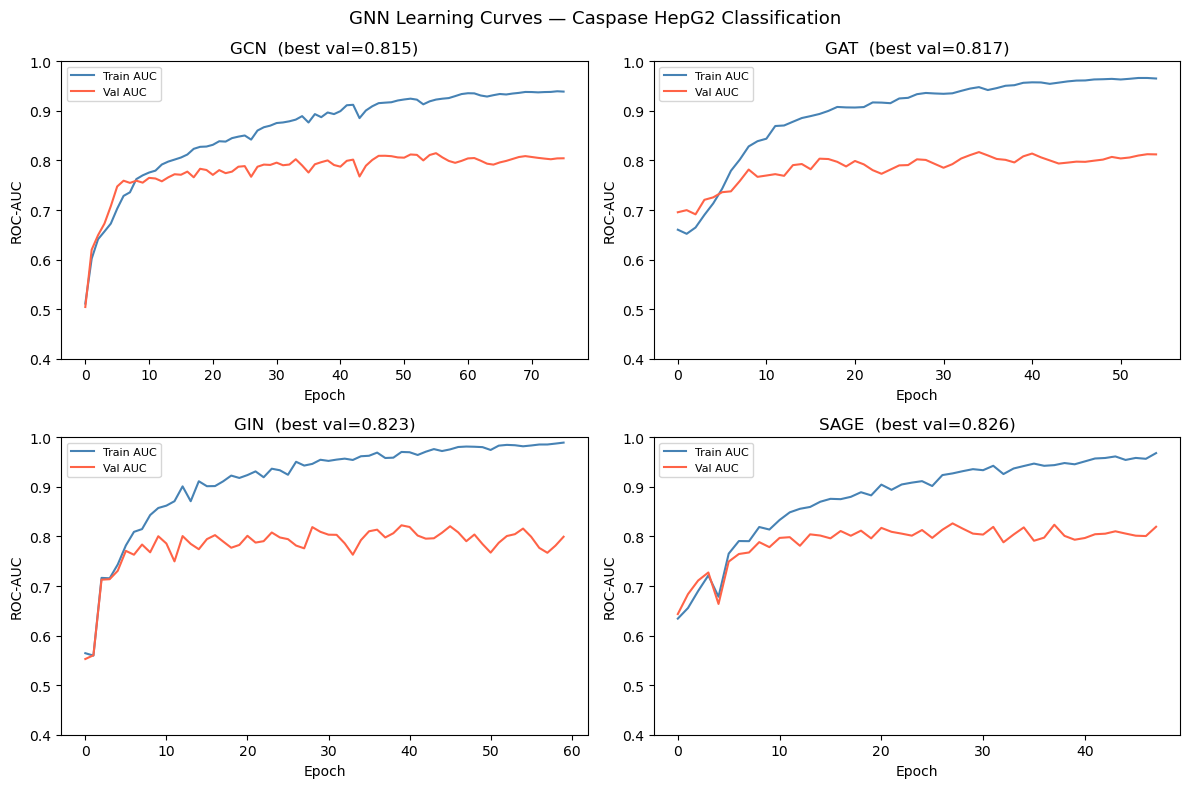

In [22]:
# ── Learning Curves ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, arch in zip(axes.ravel(), ['GCN','GAT','GIN','SAGE']):
    if arch in gnn_history:
        tr, va = gnn_history[arch]
        ax.plot(tr, label='Train AUC', color='steelblue')
        ax.plot(va, label='Val AUC',   color='tomato')
        ax.set_title(f'{arch}  (best val={gnn_best_val_auc[arch]:.3f})')
        ax.set_xlabel('Epoch'); ax.set_ylabel('ROC-AUC')
        ax.legend(fontsize=8); ax.set_ylim(0.4, 1.0)
plt.suptitle('GNN Learning Curves — Caspase HepG2 Classification', fontsize=13)
plt.tight_layout(); plt.savefig('caspase_gnn_learning_curves.png',dpi=150); plt.show()

In [23]:
# ── GNN Internal Test Evaluation ─────────────────────────────────────────────
gnn_probs_test = {}

for arch, state in gnn_best_models.items():
    cfg   = gnn_best_configs[arch]
    model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                   dropout=cfg['dropout'], conv_type=arch,
                   heads=cfg.get('heads',4)).to(DEVICE)
    model.load_state_dict(state)
    probs, _, _ = gnn_eval(model, test_loader, DEVICE)
    gnn_probs_test[arch] = probs

rows_gnn = []
for arch, prob in gnn_probs_test.items():
    for cpt in [0.5, 0.8]:
        rows_gnn.append(evaluate(y_test, prob, arch, cpt))

df_gnn_test = pd.DataFrame(rows_gnn)[METRIC_COLS]
print('── GNN — Internal Test Set ──')
display(df_gnn_test.set_index(['Model','CPT']))

── GNN — Internal Test Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  Bal-Acc  \
Model CPT                                                                     
GCN   0.5         68.0         72.2  70.1   0.7622  0.0925  0.1599     70.1   
      0.8         28.0         93.0  60.5   0.7622  0.0925  0.1414     60.5   
GAT   0.5         74.0         61.9  67.9   0.7449  0.0886  0.1324     67.9   
      0.8         46.0         85.8  65.9   0.7449  0.0886  0.1593     65.9   
GIN   0.5         74.0         69.7  71.9   0.7465  0.0940  0.1695     71.9   
      0.8         48.0         85.4  66.7   0.7465  0.0940  0.1651     66.7   
SAGE  0.5         68.0         64.6  66.3   0.7275  0.0851  0.1221     66.3   
      0.8         32.0         90.9  61.5   0.7275  0.0851  0.1389     61.5   

               F1  
Model CPT          
GCN   0.5  0.1411  
      0.8  0.1697  
GAT   0.5  0.1167  
      0.8  0.1661  
GIN   0.5  0.1420  
      0.8  0.1690  
SAGE  0.5  0.1149  
      0.8  0.1633

---
## Step 7 — Consensus Model (All Classical + GNN)

In [24]:
# ── Consensus: Average All Model Probabilities ───────────────────────────────
all_test_probs = {**cl_probs_test, **gnn_probs_test}

consensus_prob = np.mean(list(all_test_probs.values()), axis=0)
all_test_probs['Consensus'] = consensus_prob

cl_consensus  = np.mean(list(cl_probs_test.values()), axis=0)
all_test_probs['Consensus-Classical'] = cl_consensus

gnn_consensus = np.mean(list(gnn_probs_test.values()), axis=0)
all_test_probs['Consensus-GNN'] = gnn_consensus

final_rows = []
for name, prob in all_test_probs.items():
    for cpt in [0.5, 0.8]:
        final_rows.append(evaluate(y_test, prob, name, cpt))

df_final = pd.DataFrame(final_rows)[METRIC_COLS]
print('── FULL INTERNAL TEST SET COMPARISON ──')
display(df_final.set_index(['Model','CPT']))

── FULL INTERNAL TEST SET COMPARISON ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC  \
Model               CPT                                                    
Random Forest       0.5         56.0         78.6  67.3   0.7956  0.1682   
                    0.8          8.0         99.3  53.7   0.7956  0.1682   
SVM                 0.5         72.0         68.1  70.0   0.7769  0.1679   
                    0.8          6.0         99.9  52.9   0.7769  0.1679   
XGBoost             0.5         60.0         63.5  61.7   0.6946  0.0941   
                    0.8         32.0         89.4  60.7   0.6946  0.0941   
GCN                 0.5         68.0         72.2  70.1   0.7622  0.0925   
                    0.8         28.0         93.0  60.5   0.7622  0.0925   
GAT                 0.5         74.0         61.9  67.9   0.7449  0.0886   
                    0.8         46.0         85.8  65.9   0.7449  0.0886   
GIN                 0.5         74.0         69.7  71.9   0.7465  0.0940   
                    0.8         48.0         85.4  66.7   0.7465  0.0940   
SAGE                0.5         68.0         64.6  66.3   0.7275  0.0851   
                    0.8         32.0         90.9  61.5   0.7275  0.0851   
Consensus           0.5         80.0         70.6  75.3   0.7878  0.1199   
                    0.8         16.0         96.8  56.4   0.7878  0.1199   
Consensus-Classical 0.5         68.0         69.9  69.0   0.7684  0.1374   
                    0.8         14.0         98.4  56.2   0.7684  0.1374   
Consensus-GNN       0.5         70.0         68.8  69.4   0.7606  0.0995   
                    0.8         36.0         90.9  63.5   0.7606  0.0995   

                            MCC  Bal-Acc      F1  
Model               CPT                           
Random Forest       0.5  0.1493     67.3  0.1455  
                    0.8  0.1363     53.7  0.1250  
SVM                 0.5  0.1534     70.0  0.1324  
                    0.8  0.1825     52.9  0.1091  
XGBoost             0.5  0.0875     61.7  0.0993  
                    0.8  0.1219     60.7  0.1468  
GCN                 0.5  0.1599     70.1  0.1411  
                    0.8  0.1414     60.5  0.1697  
GAT                 0.5  0.1324     67.9  0.1167  
                    0.8  0.1593     65.9  0.1661  
GIN                 0.5  0.1695     71.9  0.1420  
                    0.8  0.1651     66.7  0.1690  
SAGE                0.5  0.1221     66.3  0.1149  
                    0.8  0.1389     61.5  0.1633  
Consensus           0.5  0.1971     75.3  0.1562  
                    0.8  0.1233     56.4  0.1538  
Consensus-Classical 0.5  0.1476     69.0  0.1320  
                    0.8  0.1589     56.2  0.1750  
Consensus-GNN       0.5  0.1493     69.4  0.1313  
                    0.8  0.1622     63.5  0.1818

---
## Step 8 — Applicability Domain (k-NN Jaccard)

AD threshold  : 0.7174
Test in AD    : 511/1484 (34.4%)
  AD-filtered Sensitivity: 83.9
  AD-filtered Specificity: 69.6
  AD-filtered CCR: 76.7
  AD-filtered ROC-AUC: 0.8257
  AD-filtered MCC: 0.27


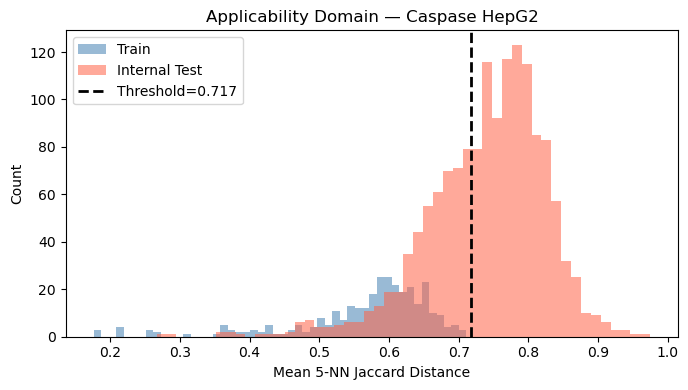

In [25]:
# ── AD — k-NN Jaccard ────────────────────────────────────────────────────────
nn_ad = NearestNeighbors(n_neighbors=5, metric='jaccard', n_jobs=-1)
nn_ad.fit(X_train)
d_tr, _ = nn_ad.kneighbors(X_train)
md_tr   = d_tr.mean(axis=1)
ad_thr  = md_tr.mean() + 1.5*md_tr.std()

d_te, _ = nn_ad.kneighbors(X_test)
md_te   = d_te.mean(axis=1)
in_ad   = md_te <= ad_thr
cov     = in_ad.mean()*100

print(f'AD threshold  : {ad_thr:.4f}')
print(f'Test in AD    : {in_ad.sum()}/{len(y_test)} ({cov:.1f}%)')

if in_ad.sum() >= 20:
    m = evaluate(y_test[in_ad], consensus_prob[in_ad], 'Consensus AD', cpt=0.5)
    for k in ['Sensitivity','Specificity','CCR','ROC-AUC','MCC']:
        print(f'  AD-filtered {k}: {m[k]}')

fig, ax = plt.subplots(figsize=(7,4))
ax.hist(md_tr, bins=50, alpha=0.55, color='steelblue', label='Train')
ax.hist(md_te, bins=50, alpha=0.55, color='tomato',    label='Internal Test')
ax.axvline(ad_thr, color='black', linestyle='--', lw=2,
           label=f'Threshold={ad_thr:.3f}')
ax.set_xlabel('Mean 5-NN Jaccard Distance'); ax.set_ylabel('Count')
ax.set_title('Applicability Domain — Caspase HepG2'); ax.legend()
plt.tight_layout(); plt.savefig('caspase_ad_dist.png',dpi=150); plt.show()

---
## Step 9 — Internal Test Summary

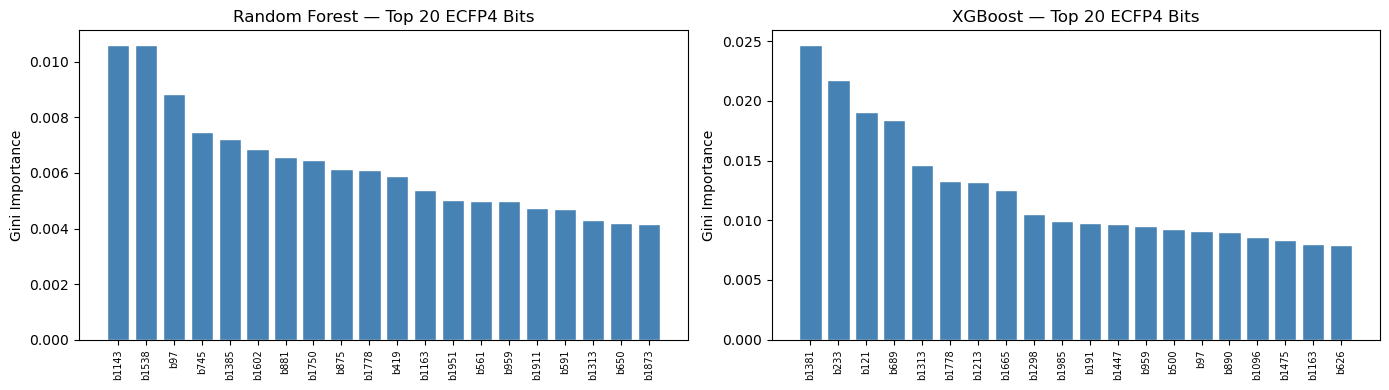

In [26]:
# ── Feature Importance — RF & XGBoost ────────────────────────────────────────
fig, axes = plt.subplots(1,2,figsize=(14,4))
for ax,(name,clf) in zip(axes,[('Random Forest',best_rf),('XGBoost',best_xgb)]):
    imp = clf.feature_importances_
    top = np.argsort(imp)[::-1][:20]
    ax.bar(range(20), imp[top], color='steelblue', edgecolor='white')
    ax.set_xticks(range(20))
    ax.set_xticklabels([f'b{i}' for i in top], rotation=90, fontsize=7)
    ax.set_title(f'{name} — Top 20 ECFP4 Bits'); ax.set_ylabel('Gini Importance')
plt.tight_layout(); plt.savefig('caspase_feat_importance.png',dpi=150); plt.show()

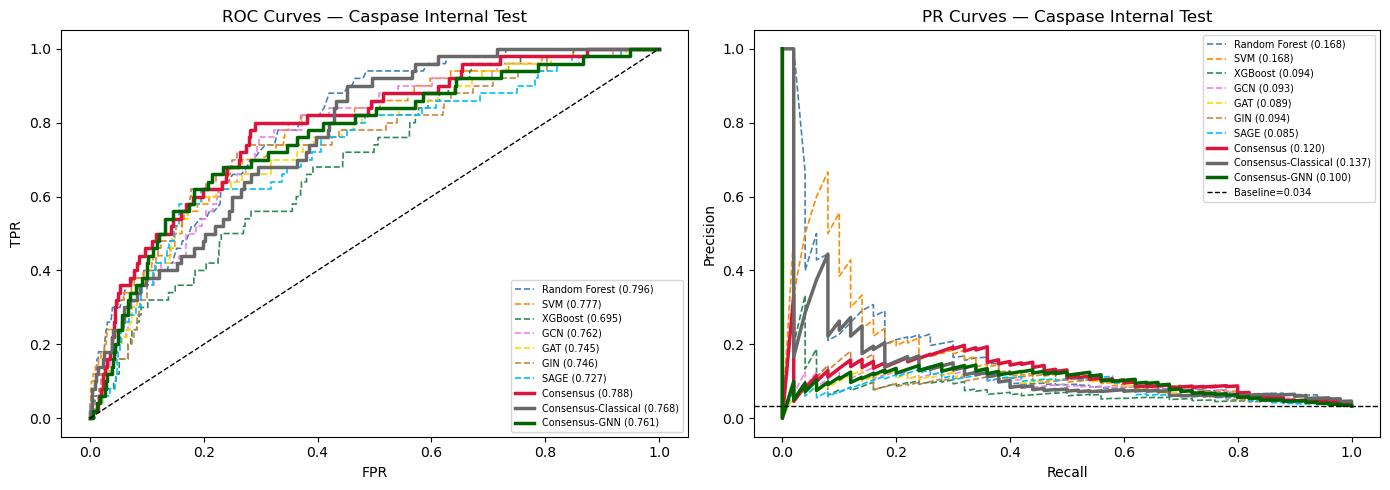

In [27]:
# ── ROC / PR Curves — Internal Test ─────────────────────────────────────────
COLORS = {'Random Forest':'steelblue','SVM':'darkorange','XGBoost':'seagreen',
          'GCN':'violet','GAT':'gold','GIN':'peru','SAGE':'deepskyblue',
          'Consensus':'crimson','Consensus-Classical':'dimgray','Consensus-GNN':'darkgreen'}

fig, axes = plt.subplots(1,2,figsize=(14,5))
for name, prob in all_test_probs.items():
    lw = 2.5 if 'Consensus' in name else 1.2
    c  = COLORS.get(name,'gray')
    ls = '-' if name in ['Consensus','Consensus-Classical','Consensus-GNN'] else '--'
    fpr,tpr,_ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    axes[0].plot(fpr,tpr, lw=lw, color=c, ls=ls, label=f'{name} ({auc:.3f})')
    pre,rec,_ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    axes[1].plot(rec,pre, lw=lw, color=c, ls=ls, label=f'{name} ({ap:.3f})')

axes[0].plot([0,1],[0,1],'k--',lw=1)
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[0].set_title('ROC Curves — Caspase Internal Test'); axes[0].legend(fontsize=7,loc='lower right')

axes[1].axhline(y_test.mean(),color='k',ls='--',lw=1,label=f'Baseline={y_test.mean():.3f}')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('PR Curves — Caspase Internal Test'); axes[1].legend(fontsize=7,loc='upper right')

plt.tight_layout(); plt.savefig('caspase_roc_pr_internal.png',dpi=150); plt.show()

In [28]:
# ── Ranked Summary Table ─────────────────────────────────────────────────────
summary_cpt1 = df_final[df_final['CPT']==0.5].drop(columns='CPT').set_index('Model')
summary_sorted = summary_cpt1.sort_values('ROC-AUC', ascending=False)
print('='*90)
print('FINAL RANKING — Caspase HepG2 Binary Toxicity (CPT=0.50)')
print('80/20/20 split | 1:1 downsampling | Morgan ECFP4 + GNN atom/bond features')
print('='*90)
display(summary_sorted)

print(f'\nApplicability Domain coverage: {cov:.1f}%')
summary_sorted.to_csv('caspase_internal_results.csv')
print('Saved → caspase_internal_results.csv')

FINAL RANKING — Caspase HepG2 Binary Toxicity (CPT=0.50)
80/20/20 split | 1:1 downsampling | Morgan ECFP4 + GNN atom/bond features


,Sensitivity,Specificity,CCR,ROC-AUC,PR-AUC,MCC,Bal-Acc,F1
Model,,,,,,,,
Random Forest,56.0,78.6,67.3,0.7956,0.1682,0.1493,67.3,0.1455
Consensus,80.0,70.6,75.3,0.7878,0.1199,0.1971,75.3,0.1562
SVM,72.0,68.1,70.0,0.7769,0.1679,0.1534,70.0,0.1324
Consensus-Classical,68.0,69.9,69.0,0.7684,0.1374,0.1476,69.0,0.1320
GCN,68.0,72.2,70.1,0.7622,0.0925,0.1599,70.1,0.1411
Consensus-GNN,70.0,68.8,69.4,0.7606,0.0995,0.1493,69.4,0.1313
GIN,74.0,69.7,71.9,0.7465,0.0940,0.1695,71.9,0.1420
GAT,74.0,61.9,67.9,0.7449,0.0886,0.1324,67.9,0.1167
SAGE,68.0,64.6,66.3,0.7275,0.0851,0.1221,66.3,0.1149



Applicability Domain coverage: 34.4%
Saved → caspase_internal_results.csv


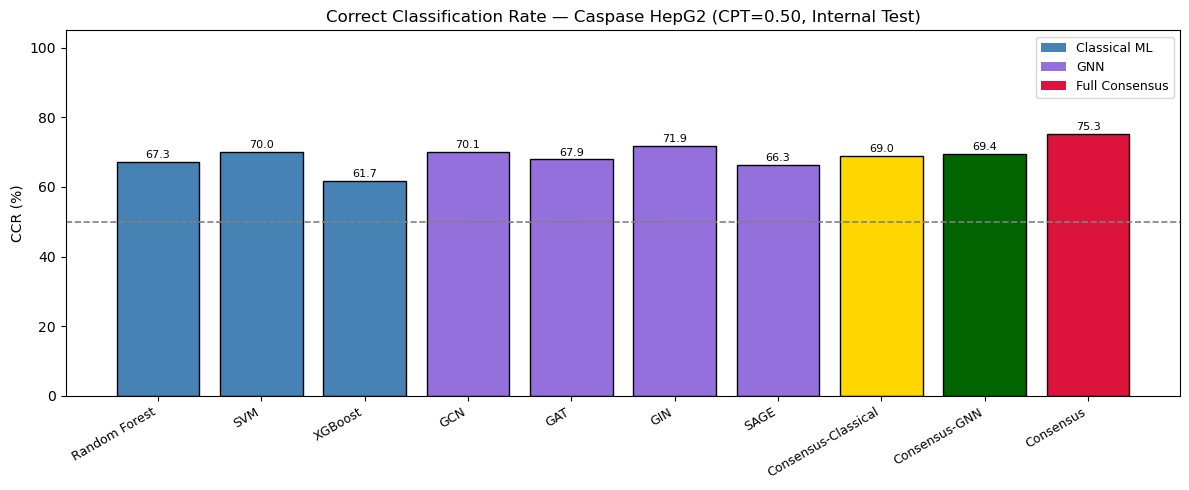

In [29]:
# ── CCR Comparison Bar Chart ─────────────────────────────────────────────────
models_to_plot = ['Random Forest','SVM','XGBoost','GCN','GAT','GIN','SAGE',
                  'Consensus-Classical','Consensus-GNN','Consensus']
ccr_vals = [summary_cpt1.loc[m,'CCR'] if m in summary_cpt1.index else 0 for m in models_to_plot]
colors_bar = ['steelblue']*3 + ['mediumpurple']*4 + ['gold','darkgreen','crimson']

fig, ax = plt.subplots(figsize=(12,5))
bars = ax.bar(models_to_plot, ccr_vals, color=colors_bar, edgecolor='black')
ax.axhline(50, color='gray', linestyle='--', lw=1.2, label='Chance (50%)')
ax.set_ylabel('CCR (%)'); ax.set_ylim(0,105)
ax.set_title('Correct Classification Rate — Caspase HepG2 (CPT=0.50, Internal Test)')
ax.set_xticklabels(models_to_plot, rotation=30, ha='right', fontsize=9)
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=8)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor='steelblue',label='Classical ML'),
                   Patch(facecolor='mediumpurple',label='GNN'),
                   Patch(facecolor='crimson',label='Full Consensus')], fontsize=9)
plt.tight_layout(); plt.savefig('caspase_ccr_internal.png',dpi=150); plt.show()

Best model (ROC-AUC): Random Forest
              precision    recall  f1-score   support

 Inactive(0)       0.98      0.79      0.87      1434
   Active(1)       0.08      0.56      0.15        50

    accuracy                           0.78      1484
   macro avg       0.53      0.67      0.51      1484
weighted avg       0.95      0.78      0.85      1484



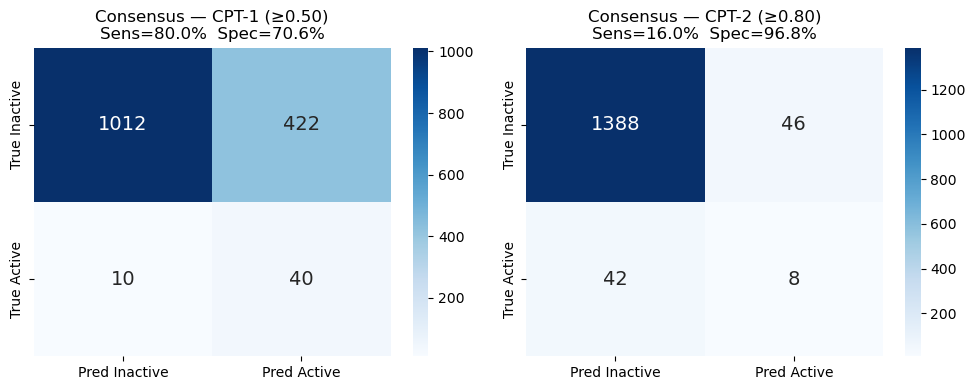

In [30]:
# ── Confusion Matrix — Consensus ─────────────────────────────────────────────
best_name = summary_sorted.index[0]
best_prob = all_test_probs[best_name]
best_pred = (best_prob >= 0.5).astype(int)
print(f'Best model (ROC-AUC): {best_name}')
print(classification_report(y_test, best_pred, target_names=['Inactive(0)','Active(1)']))

fig, axes = plt.subplots(1,2,figsize=(10,4))
for ax, cpt, label in zip(axes,[0.5,0.8],['CPT-1 (≥0.50)','CPT-2 (≥0.80)']):
    pred = (consensus_prob >= cpt).astype(int)
    cm   = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Pred Inactive','Pred Active'],
                yticklabels=['True Inactive','True Active'], annot_kws={'size':14})
    tn,fp,fn,tp = cm.ravel()
    sens = tp/(tp+fn); spec = tn/(tn+fp)
    ax.set_title(f'Consensus — {label}\nSens={sens*100:.1f}%  Spec={spec*100:.1f}%')
plt.tight_layout(); plt.savefig('caspase_confusion_internal.png',dpi=150); plt.show()

---
## Step 10 — External Test Set: In Vivo Liver Injury (LTKB-BD DILI)

Three PubChem bioassays from the FDA's Liver Toxicity Knowledge Base (LTKB-BD):

| Assay | DILI Category | Description |
|-------|--------------|-------------|
| AID_625276 | Most-concern | Fatal hepatotoxicity, acute liver failure |
| AID_625277 | Less-concern | Aminotransferases increase, jaundice, cholestasis |
| AID_625278 | No-concern | Negative controls |

**DILI binary label**: 1 = DILI concern (scored entries in AID_625276/625277), 0 = no concern (AID_625278).

**Goal**: Test whether the Caspase HepG2 QSAR model (ECFP4 + GNN) translates to in vivo DILI prediction.

In [31]:
# ── E1. Load & Label Liver DILI Data ─────────────────────────────────────────
cols_keep = ['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES',
             'dili_label', 'dili_source', 'dili_severity_score']
liver_dfs = []

# AID_625276 — Most-concern DILI
df76 = pd.read_csv('liver/AID_625276_datatable.csv', low_memory=False)
df76 = df76[df76['Standard Type'] == 'LTKB_BD DILI severity score'].copy()
df76['dili_severity_score'] = pd.to_numeric(df76['Standard Value'], errors='coerce')
df76['dili_label']   = df76['dili_severity_score'].apply(lambda v: 1 if pd.notna(v) else np.nan)
df76['dili_source']  = 'AID_625276 (Most-concern)'
df76 = df76[df76['dili_label'].notna()].copy()
df76['dili_label']   = df76['dili_label'].astype(int)
liver_dfs.append(df76[cols_keep])

# AID_625277 — Less-concern DILI
df77 = pd.read_csv('liver/AID_625277_datatable.csv', low_memory=False)
df77 = df77[df77['Standard Type'] == 'LTKB_BD DILI severity score'].copy()
df77['dili_severity_score'] = pd.to_numeric(df77['Standard Value'], errors='coerce')
df77['dili_label']   = df77['dili_severity_score'].apply(lambda v: 1 if pd.notna(v) else np.nan)
df77['dili_source']  = 'AID_625277 (Less-concern)'
df77 = df77[df77['dili_label'].notna()].copy()
df77['dili_label']   = df77['dili_label'].astype(int)
liver_dfs.append(df77[cols_keep])

# AID_625278 — No-concern DILI (label = 0)
df78 = pd.read_csv('liver/AID_625278_datatable.csv', low_memory=False)
df78 = df78[df78['Standard Type'] == 'LTKB_BD DILI severity score'].copy()
df78['dili_label']          = 0
df78['dili_source']         = 'AID_625278 (No-concern)'
df78['dili_severity_score'] = np.nan
liver_dfs.append(df78[cols_keep])

df_liver = pd.concat(liver_dfs, ignore_index=True)

# Canonicalize + dedup
df_liver['csmi'] = df_liver['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(canonicalize)
df_liver = df_liver.dropna(subset=['csmi']).reset_index(drop=True)
df_liver = df_liver.drop_duplicates('csmi', keep='first').reset_index(drop=True)

print(f'Liver DILI compounds  : {len(df_liver):,}')
print(df_liver['dili_label'].value_counts())
print(df_liver['dili_source'].value_counts())

Liver DILI compounds  : 218
dili_label
1    157
0     61
Name: count, dtype: int64
dili_source
AID_625277 (Less-concern)    83
AID_625276 (Most-concern)    74
AID_625278 (No-concern)      61
Name: count, dtype: int64


[19:00:05] SMILES Parse Error: syntax error while parsing: nan
[19:00:05] SMILES Parse Error: check for mistakes around position 2:
[19:00:05] nan
[19:00:05] ~^
[19:00:05] SMILES Parse Error: Failed parsing SMILES 'nan' for input: 'nan'
[19:00:05] SMILES Parse Error: syntax error while parsing: nan
[19:00:05] SMILES Parse Error: check for mistakes around position 2:
[19:00:05] nan
[19:00:05] ~^
[19:00:05] SMILES Parse Error: Failed parsing SMILES 'nan' for input: 'nan'
[19:00:05] SMILES Parse Error: syntax error while parsing: nan
[19:00:05] SMILES Parse Error: check for mistakes around position 2:
[19:00:05] nan
[19:00:05] ~^
[19:00:05] SMILES Parse Error: Failed parsing SMILES 'nan' for input: 'nan'
[19:00:05] SMILES Parse Error: syntax error while parsing: nan
[19:00:05] SMILES Parse Error: check for mistakes around position 2:
[19:00:05] nan
[19:00:05] ~^
[19:00:05] SMILES Parse Error: Failed parsing SMILES 'nan' for input: 'nan'
[19:00:05] SMILES Parse Error: syntax error while pa

In [32]:
# ── E2. Overlap Check: Liver SMILES vs Caspase Training Set ──────────────────
caspase_smiles = set(df['csmi'].values)
liver_smiles   = set(df_liver['csmi'].values)

overlap     = caspase_smiles & liver_smiles
overlap_pct = 100 * len(overlap) / len(liver_smiles) if liver_smiles else 0

print(f'Caspase training compounds : {len(caspase_smiles):,}')
print(f'Liver DILI compounds       : {len(liver_smiles):,}')
print(f'SMILES overlap             : {len(overlap):,}  ({overlap_pct:.1f}% of liver set)')
print(f'Truly external (no overlap): {len(liver_smiles)-len(overlap):,}  ({100-overlap_pct:.1f}%)')
print('(Even overlapping SMILES are treated as external — different endpoint: DILI vs caspase activation)')

Caspase training compounds : 7,420
Liver DILI compounds       : 218
SMILES overlap             : 128  (58.7% of liver set)
Truly external (no overlap): 90  (41.3%)
(Even overlapping SMILES are treated as external — different endpoint: DILI vs caspase activation)


In [33]:
# ── E3. ECFP4 Fingerprints + Graphs for Liver Compounds ──────────────────────
liver_fps_raw = df_liver['csmi'].apply(smiles_to_ecfp4)
valid_fp      = liver_fps_raw.notna()
df_liver      = df_liver[valid_fp].reset_index(drop=True)
X_liver       = np.vstack(liver_fps_raw[valid_fp].values)
y_liver       = df_liver['dili_label'].values

# Build graphs
graphs_liver, valid_graph_idx = [], []
for i, (smi, lbl) in enumerate(zip(df_liver['csmi'].values, y_liver)):
    g = mol_to_graph(smi, lbl)
    if g is not None:
        graphs_liver.append(g)
        valid_graph_idx.append(i)

valid_graph_idx = np.array(valid_graph_idx)
X_liver_gnn    = X_liver[valid_graph_idx]
y_liver_gnn    = y_liver[valid_graph_idx]
df_liver_gnn   = df_liver.iloc[valid_graph_idx].reset_index(drop=True)
liver_loader   = DataLoader(graphs_liver, batch_size=64, shuffle=False)

print(f'Liver fingerprint matrix : {X_liver.shape}')
print(f'Valid graphs             : {len(graphs_liver)} / {len(df_liver)}')
print(f'FP density — liver       : {X_liver.mean():.4f}  (train: {X_train.mean():.4f})')
print(f'DILI concern in GNN set  : {(y_liver_gnn==1).sum()} / {len(y_liver_gnn)}')

Liver fingerprint matrix : (218, 2048)
Valid graphs             : 218 / 218
FP density — liver       : 0.0195  (train: 0.0159)
DILI concern in GNN set  : 157 / 218


[19:00:05] DEPRECATION WARNING: please use MorganGenerator
[19:00:05] DEPRECATION WARNING: please use MorganGenerator
[19:00:05] DEPRECATION WARNING: please use MorganGenerator
[19:00:05] DEPRECATION WARNING: please use MorganGenerator
[19:00:05] DEPRECATION WARNING: please use MorganGenerator
[19:00:05] DEPRECATION WARNING: please use MorganGenerator
[19:00:05] DEPRECATION WARNING: please use MorganGenerator
[19:00:05] DEPRECATION WARNING: please use MorganGenerator
[19:00:05] DEPRECATION WARNING: please use MorganGenerator
[19:00:05] DEPRECATION WARNING: please use MorganGenerator
[19:00:05] DEPRECATION WARNING: please use MorganGenerator
[19:00:05] DEPRECATION WARNING: please use MorganGenerator
[19:00:05] DEPRECATION WARNING: please use MorganGenerator
[19:00:05] DEPRECATION WARNING: please use MorganGenerator
[19:00:05] DEPRECATION WARNING: please use MorganGenerator
[19:00:05] DEPRECATION WARNING: please use MorganGenerator
[19:00:05] DEPRECATION WARNING: please use MorganGenerat

AD threshold              : 0.7174
Liver compounds in AD     : 47/218 (21.6%)
  DILI-concern (1) in AD  : 37 / 157
  No-concern   (0) in AD  : 10 / 61


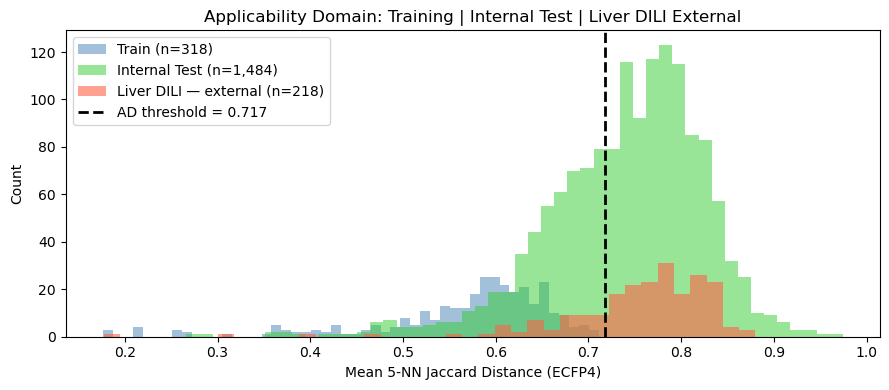

In [34]:
# ── E4. Applicability Domain — Liver Compounds ────────────────────────────────
d_liver, _   = nn_ad.kneighbors(X_liver)
md_liver     = d_liver.mean(axis=1)
in_ad_liver  = md_liver <= ad_thr

print(f'AD threshold              : {ad_thr:.4f}')
print(f'Liver compounds in AD     : {in_ad_liver.sum()}/{len(y_liver)} ({in_ad_liver.mean()*100:.1f}%)')
print(f'  DILI-concern (1) in AD  : {(in_ad_liver & (y_liver==1)).sum()} / {(y_liver==1).sum()}')
print(f'  No-concern   (0) in AD  : {(in_ad_liver & (y_liver==0)).sum()} / {(y_liver==0).sum()}')

fig, ax = plt.subplots(figsize=(9,4))
ax.hist(md_tr,    bins=50, alpha=0.5, color='steelblue', label=f'Train (n={len(md_tr):,})')
ax.hist(md_te,    bins=50, alpha=0.5, color='limegreen', label=f'Internal Test (n={len(md_te):,})')
ax.hist(md_liver, bins=40, alpha=0.6, color='tomato',    label=f'Liver DILI — external (n={len(md_liver):,})')
ax.axvline(ad_thr, color='black', linestyle='--', lw=2, label=f'AD threshold = {ad_thr:.3f}')
ax.set_xlabel('Mean 5-NN Jaccard Distance (ECFP4)')
ax.set_ylabel('Count')
ax.set_title('Applicability Domain: Training | Internal Test | Liver DILI External')
ax.legend(); plt.tight_layout()
plt.savefig('caspase_ad_liver_external.png', dpi=150); plt.show()

In [35]:
# ── E5. Classical ML — Liver DILI Evaluation ─────────────────────────────────
cl_probs_liver = {n: clf.predict_proba(X_liver)[:,1] for n, clf in classical.items()}

rows_liver_cl = []
for name in classical:
    for cpt in [0.5, 0.8]:
        rows_liver_cl.append(evaluate(y_liver, cl_probs_liver[name], name, cpt))

df_liver_cl = pd.DataFrame(rows_liver_cl)[METRIC_COLS]
print('── Classical ML — Liver DILI External Test ──')
display(df_liver_cl.set_index(['Model','CPT']))

── Classical ML — Liver DILI External Test ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  \
Model         CPT                                                            
Random Forest 0.5         37.6         65.6  51.6   0.5606  0.7709  0.0294   
              0.8          5.1        100.0  52.5   0.5606  0.7709  0.1217   
SVM           0.5         56.1         44.3  50.2   0.5502  0.7659  0.0028   
              0.8          4.5        100.0  52.2   0.5502  0.7659  0.1135   
XGBoost       0.5         42.7         67.2  54.9   0.6003  0.7789  0.0906   
              0.8         17.2         88.5  52.9   0.6003  0.7789  0.0708   

                   Bal-Acc      F1  
Model         CPT                   
Random Forest 0.5     51.6  0.4979  
              0.8     52.5  0.0970  
SVM           0.5     50.2  0.6308  
              0.8     52.2  0.0854  
XGBoost       0.5     54.9  0.5492  
              0.8     52.9  0.2827

In [36]:
# ── E6. GNN — Liver DILI Evaluation ──────────────────────────────────────────
gnn_probs_liver = {}
for arch, state in gnn_best_models.items():
    cfg   = gnn_best_configs[arch]
    model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                   dropout=cfg['dropout'], conv_type=arch,
                   heads=cfg.get('heads', 4)).to(DEVICE)
    model.load_state_dict(state)
    probs_g, _, _ = gnn_eval(model, liver_loader, DEVICE)
    gnn_probs_liver[arch] = probs_g

rows_liver_gnn = []
for arch, prob in gnn_probs_liver.items():
    for cpt in [0.5, 0.8]:
        rows_liver_gnn.append(evaluate(y_liver_gnn, prob, arch, cpt))

df_liver_gnn_res = pd.DataFrame(rows_liver_gnn)[METRIC_COLS]
print('── GNN — Liver DILI External Test ──')
display(df_liver_gnn_res.set_index(['Model','CPT']))

── GNN — Liver DILI External Test ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  Bal-Acc  \
Model CPT                                                                     
GCN   0.5         38.2         80.3  59.3   0.6538  0.8234  0.1770     59.3   
      0.8          5.7         98.4  52.0   0.6538  0.8234  0.0878     52.0   
GAT   0.5         50.3         65.6  57.9   0.6249  0.8089  0.1432     57.9   
      0.8         17.2         95.1  56.1   0.6249  0.8089  0.1600     56.1   
GIN   0.5         40.1         77.0  58.6   0.6281  0.8028  0.1613     58.6   
      0.8         19.7         88.5  54.1   0.6281  0.8028  0.0979     54.1   
SAGE  0.5         42.7         55.7  49.2   0.5265  0.7465 -0.0144     49.2   
      0.8          8.9         96.7  52.8   0.5265  0.7465  0.0971     52.8   

               F1  
Model CPT          
GCN   0.5  0.5240  
      0.8  0.1078  
GAT   0.5  0.6148  
      0.8  0.2888  
GIN   0.5  0.5385  
      0.8  0.3179  
SAGE  0.5  0.5339  
      0.8  0.1618

In [37]:
# ── E7. Consensus — Liver DILI Full Summary ───────────────────────────────────
# Use GNN-valid subset for all models to ensure consistent sample sizes
cl_probs_liver_gnn = {n: clf.predict_proba(X_liver_gnn)[:,1] for n, clf in classical.items()}
all_liver_probs    = {**cl_probs_liver_gnn, **gnn_probs_liver}

liver_consensus     = np.mean(list(all_liver_probs.values()), axis=0)
liver_cl_consensus  = np.mean(list(cl_probs_liver_gnn.values()), axis=0)
liver_gnn_consensus = np.mean(list(gnn_probs_liver.values()), axis=0)

all_liver_probs['Consensus']           = liver_consensus
all_liver_probs['Consensus-Classical'] = liver_cl_consensus
all_liver_probs['Consensus-GNN']       = liver_gnn_consensus

final_liver_rows = []
for name, prob in all_liver_probs.items():
    for cpt in [0.5, 0.8]:
        final_liver_rows.append(evaluate(y_liver_gnn, prob, name, cpt))

df_liver_final = pd.DataFrame(final_liver_rows)[METRIC_COLS]
summary_liver  = df_liver_final[df_liver_final['CPT'] == 0.5].set_index('Model').drop(columns='CPT')
summary_liver_sorted = summary_liver.sort_values('ROC-AUC', ascending=False)

print('='*90)
print('EXTERNAL TEST SET — LIVER DILI (LTKB-BD, AID_625276/625277/625278)')
print('Model trained on: Caspase HepG2 (combined_hepg2_caspase) | ECFP4 + GNN atom/bond features')
print('='*90)
display(summary_liver_sorted)
summary_liver_sorted.to_csv('caspase_liver_dili_external_results.csv')
print('Saved → caspase_liver_dili_external_results.csv')

EXTERNAL TEST SET — LIVER DILI (LTKB-BD, AID_625276/625277/625278)
Model trained on: Caspase HepG2 (combined_hepg2_caspase) | ECFP4 + GNN atom/bond features


,Sensitivity,Specificity,CCR,ROC-AUC,PR-AUC,MCC,Bal-Acc,F1
Model,,,,,,,,
GCN,38.2,80.3,59.3,0.6538,0.8234,0.1770,59.3,0.5240
GIN,40.1,77.0,58.6,0.6281,0.8028,0.1613,58.6,0.5385
GAT,50.3,65.6,57.9,0.6249,0.8089,0.1432,57.9,0.6148
Consensus-GNN,45.2,72.1,58.7,0.6186,0.8006,0.1588,58.7,0.5796
Consensus,46.5,65.6,56.0,0.6110,0.7961,0.1094,56.0,0.5817
XGBoost,42.7,67.2,54.9,0.6003,0.7789,0.0906,54.9,0.5492
Consensus-Classical,43.9,67.2,55.6,0.5788,0.7805,0.1019,55.6,0.5610
Random Forest,37.6,65.6,51.6,0.5606,0.7709,0.0294,51.6,0.4979
SVM,56.1,44.3,50.2,0.5502,0.7659,0.0028,50.2,0.6308


Saved → caspase_liver_dili_external_results.csv


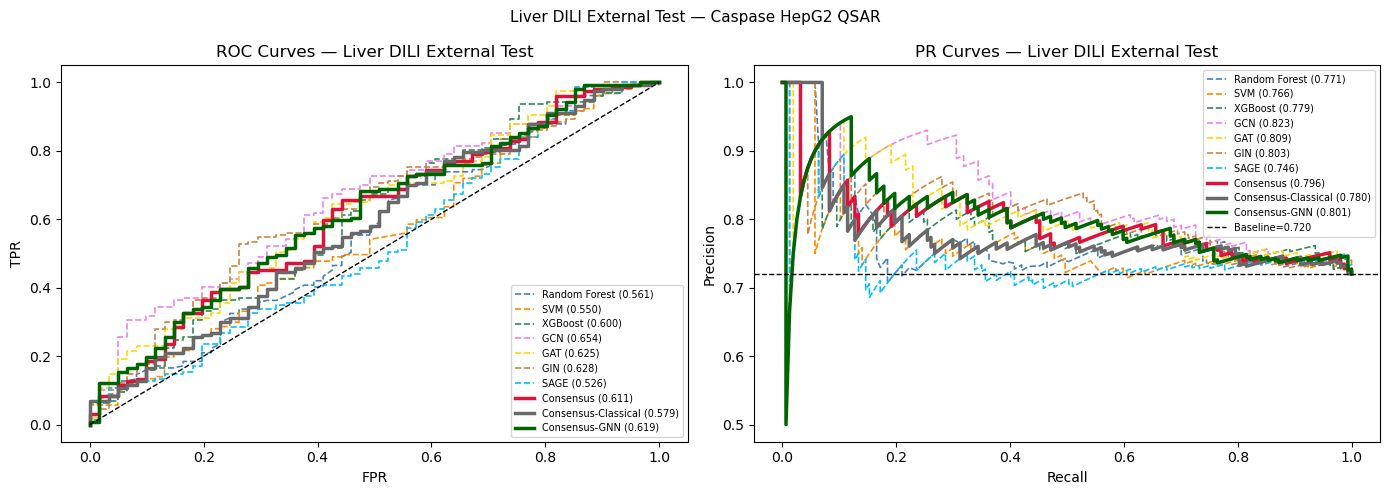

In [38]:
# ── E8. ROC / PR Curves — Liver DILI External Test ───────────────────────────
COLORS_L = {'Random Forest':'steelblue','SVM':'darkorange','XGBoost':'seagreen',
            'GCN':'violet','GAT':'gold','GIN':'peru','SAGE':'deepskyblue',
            'Consensus':'crimson','Consensus-Classical':'dimgray','Consensus-GNN':'darkgreen'}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, prob in all_liver_probs.items():
    lw = 2.5 if 'Consensus' in name else 1.2
    c  = COLORS_L.get(name, 'gray')
    ls = '-' if name in ['Consensus','Consensus-Classical','Consensus-GNN'] else '--'
    fpr, tpr, _ = roc_curve(y_liver_gnn, prob)
    auc = roc_auc_score(y_liver_gnn, prob)
    axes[0].plot(fpr, tpr, lw=lw, color=c, ls=ls, label=f'{name} ({auc:.3f})')
    pre, rec, _ = precision_recall_curve(y_liver_gnn, prob)
    ap = average_precision_score(y_liver_gnn, prob)
    axes[1].plot(rec, pre, lw=lw, color=c, ls=ls, label=f'{name} ({ap:.3f})')

axes[0].plot([0,1],[0,1],'k--',lw=1)
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[0].set_title('ROC Curves — Liver DILI External Test')
axes[0].legend(fontsize=7, loc='lower right')

axes[1].axhline(y_liver_gnn.mean(), color='k', ls='--', lw=1,
                label=f'Baseline={y_liver_gnn.mean():.3f}')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('PR Curves — Liver DILI External Test')
axes[1].legend(fontsize=7, loc='upper right')

plt.suptitle('Liver DILI External Test — Caspase HepG2 QSAR', fontsize=11)
plt.tight_layout(); plt.savefig('caspase_roc_pr_liver_external.png', dpi=150); plt.show()

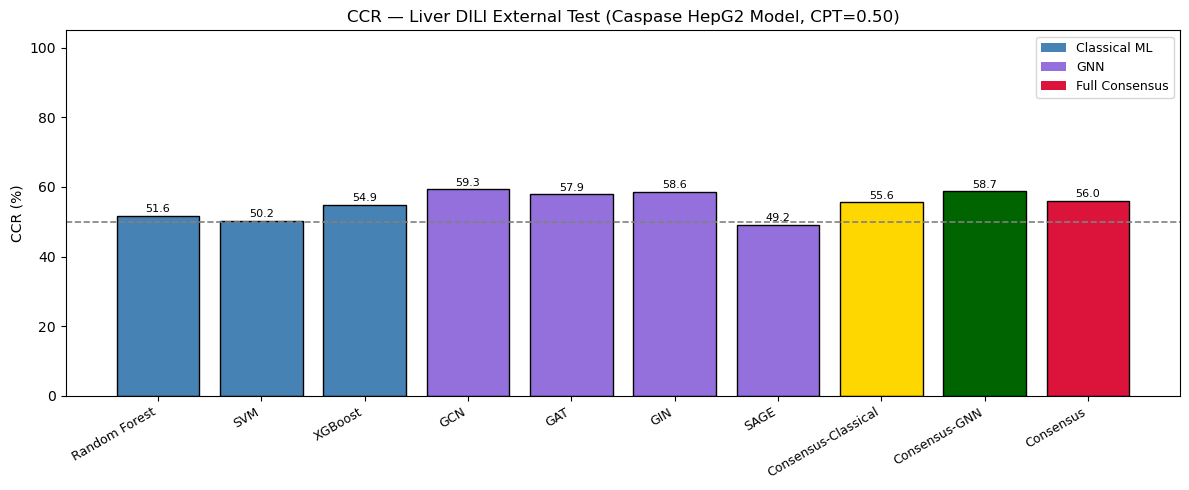


AD-filtered: 47 / 218 liver compounds inside AD (21.6%)
  Sensitivity  : 62.2%
  Specificity  : 80.0%
  CCR          : 71.1%
  ROC-AUC      : 0.6703
  MCC          : 0.3458


In [39]:
# ── E9. CCR Bar Chart + AD-Filtered Evaluation ────────────────────────────────
models_to_plot = ['Random Forest','SVM','XGBoost','GCN','GAT','GIN','SAGE',
                  'Consensus-Classical','Consensus-GNN','Consensus']
ccr_vals   = [summary_liver.loc[m,'CCR'] if m in summary_liver.index else 0
              for m in models_to_plot]
colors_bar = ['steelblue']*3 + ['mediumpurple']*4 + ['gold','darkgreen','crimson']

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(models_to_plot, ccr_vals, color=colors_bar, edgecolor='black')
ax.axhline(50, color='gray', linestyle='--', lw=1.2, label='Chance (50%)')
ax.set_ylabel('CCR (%)'); ax.set_ylim(0, 105)
ax.set_title('CCR — Liver DILI External Test (Caspase HepG2 Model, CPT=0.50)')
ax.set_xticklabels(models_to_plot, rotation=30, ha='right', fontsize=9)
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=8)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor='steelblue', label='Classical ML'),
                   Patch(facecolor='mediumpurple', label='GNN'),
                   Patch(facecolor='crimson', label='Full Consensus')], fontsize=9)
plt.tight_layout(); plt.savefig('caspase_ccr_liver_external.png', dpi=150); plt.show()

# AD-filtered evaluation
in_ad_liver_gnn = in_ad_liver[valid_graph_idx]
n_in_ad = in_ad_liver_gnn.sum()
print(f'\nAD-filtered: {n_in_ad} / {len(y_liver_gnn)} liver compounds inside AD ({n_in_ad/len(y_liver_gnn)*100:.1f}%)')
if n_in_ad >= 10:
    m_ad = evaluate(y_liver_gnn[in_ad_liver_gnn],
                    liver_consensus[in_ad_liver_gnn], 'Consensus (AD-filtered)')
    print(f'  Sensitivity  : {m_ad["Sensitivity"]}%')
    print(f'  Specificity  : {m_ad["Specificity"]}%')
    print(f'  CCR          : {m_ad["CCR"]}%')
    print(f'  ROC-AUC      : {m_ad["ROC-AUC"]}')
    print(f'  MCC          : {m_ad["MCC"]}')
else:
    print('  Too few AD-filtered compounds for meaningful evaluation.')

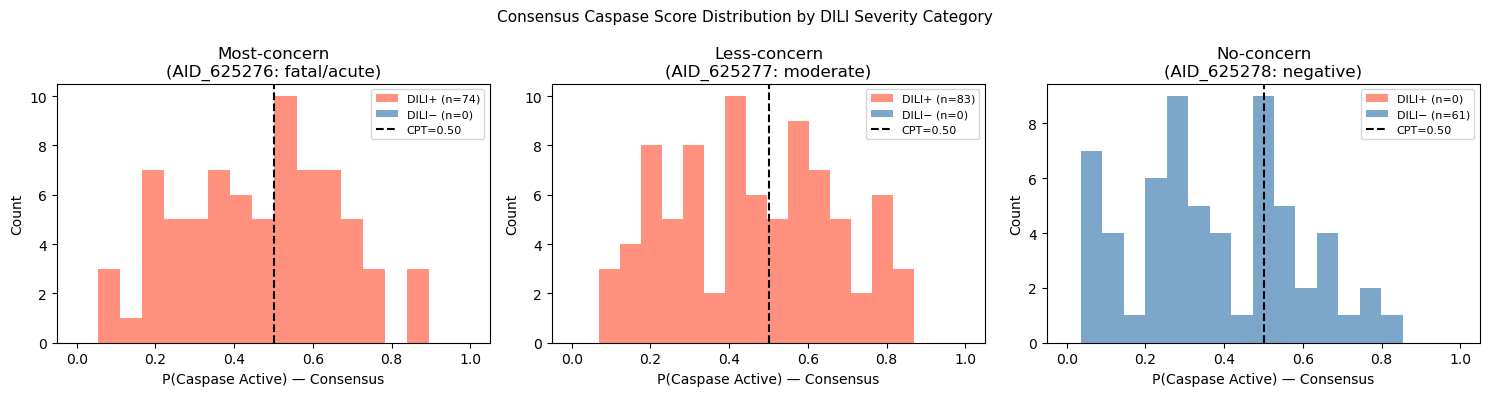

Spearman rho (DILI severity score vs P(caspase active)): 0.009  (p=0.9064)
Interpretation: positive correlation between in vitro caspase prediction and in vivo DILI severity.


In [40]:
# ── E10. Per-Severity Breakdown ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
categories = {
    'Most-concern\n(AID_625276: fatal/acute)': df_liver_gnn['dili_source'].str.contains('AID_625276'),
    'Less-concern\n(AID_625277: moderate)':    df_liver_gnn['dili_source'].str.contains('AID_625277'),
    'No-concern\n(AID_625278: negative)':       df_liver_gnn['dili_source'].str.contains('AID_625278'),
}

for ax, (title, mask) in zip(axes, categories.items()):
    mask_arr = mask.values
    p = liver_consensus[mask_arr]
    y = y_liver_gnn[mask_arr]
    ax.hist(p[y==1], bins=15, alpha=0.7, color='tomato',   label=f'DILI+ (n={y.sum()})')
    ax.hist(p[y==0], bins=15, alpha=0.7, color='steelblue',label=f'DILI− (n={(y==0).sum()})')
    ax.axvline(0.5, color='black', ls='--', lw=1.5, label='CPT=0.50')
    ax.set_xlabel('P(Caspase Active) — Consensus'); ax.set_ylabel('Count')
    ax.set_title(title); ax.legend(fontsize=8)

plt.suptitle('Consensus Caspase Score Distribution by DILI Severity Category', fontsize=11)
plt.tight_layout(); plt.savefig('caspase_liver_dili_score_dist.png', dpi=150); plt.show()

# Spearman correlation
sev_mask = df_liver_gnn['dili_severity_score'].notna()
if sev_mask.sum() > 5:
    from scipy.stats import spearmanr
    sev_scores = df_liver_gnn.loc[sev_mask, 'dili_severity_score'].values
    pred_probs  = liver_consensus[sev_mask.values]
    rho, pval   = spearmanr(sev_scores, pred_probs)
    print(f'Spearman rho (DILI severity score vs P(caspase active)): {rho:.3f}  (p={pval:.4f})')
    print(f'Interpretation: {"positive correlation" if rho>0 else "no/negative correlation"} '
          f'between in vitro caspase prediction and in vivo DILI severity.')

In [41]:
# ── E11. Comparison: Internal Caspase Test vs Liver DILI External Test ────────
internal_summary = df_final[df_final['CPT'] == 0.5].set_index('Model')
models_compare   = ['Random Forest','SVM','XGBoost','GCN','GAT','GIN','SAGE','Consensus']

comp_rows = []
for m in models_compare:
    if m in internal_summary.index and m in summary_liver.index:
        d_auc = round(internal_summary.loc[m,'ROC-AUC'] - summary_liver.loc[m,'ROC-AUC'], 4)
        comp_rows.append({
            'Model'                : m,
            'Internal ROC-AUC'     : internal_summary.loc[m, 'ROC-AUC'],
            'External ROC-AUC'     : summary_liver.loc[m, 'ROC-AUC'],
            'ΔAUC (drop)'          : d_auc,
            'Internal CCR'         : internal_summary.loc[m, 'CCR'],
            'External CCR'         : summary_liver.loc[m, 'CCR'],
            'Internal Sensitivity' : internal_summary.loc[m, 'Sensitivity'],
            'External Sensitivity' : summary_liver.loc[m, 'Sensitivity'],
            'Internal Specificity' : internal_summary.loc[m, 'Specificity'],
            'External Specificity' : summary_liver.loc[m, 'Specificity'],
        })

df_compare = pd.DataFrame(comp_rows).set_index('Model')
print('='*95)
print('COMPARISON TABLE: Internal Caspase Test vs Liver DILI External (LTKB-BD)')
print('='*95)
display(df_compare)
df_compare.to_csv('caspase_vs_liver_comparison.csv')
print('Saved → caspase_vs_liver_comparison.csv')

print(f'\nContext:')
print(f'  Training endpoint     : Caspase activation (HepG2, combined_hepg2_caspase, in vitro)')
print(f'  External endpoint     : Drug-Induced Liver Injury (LTKB-BD, in vivo)')
print(f'  Liver DILI set size   : {len(y_liver_gnn):,} compounds')
print(f'  AD coverage           : {in_ad_liver_gnn.mean()*100:.1f}% of liver compounds inside AD')
print(f'  Biological gap note   : DILI is multi-mechanism — caspase captures apoptosis only.')
print(f'                          Some AUC drop from internal to external is biologically expected.')

COMPARISON TABLE: Internal Caspase Test vs Liver DILI External (LTKB-BD)


,Internal ROC-AUC,External ROC-AUC,ΔAUC (drop),Internal CCR,External CCR,Internal Sensitivity,External Sensitivity,Internal Specificity,External Specificity
Model,,,,,,,,,
Random Forest,0.7956,0.5606,0.2350,67.3,51.6,56.0,37.6,78.6,65.6
SVM,0.7769,0.5502,0.2267,70.0,50.2,72.0,56.1,68.1,44.3
XGBoost,0.6946,0.6003,0.0943,61.7,54.9,60.0,42.7,63.5,67.2
GCN,0.7622,0.6538,0.1084,70.1,59.3,68.0,38.2,72.2,80.3
GAT,0.7449,0.6249,0.1200,67.9,57.9,74.0,50.3,61.9,65.6
GIN,0.7465,0.6281,0.1184,71.9,58.6,74.0,40.1,69.7,77.0
SAGE,0.7275,0.5265,0.2010,66.3,49.2,68.0,42.7,64.6,55.7
Consensus,0.7878,0.6110,0.1768,75.3,56.0,80.0,46.5,70.6,65.6


Saved → caspase_vs_liver_comparison.csv

Context:
  Training endpoint     : Caspase activation (HepG2, combined_hepg2_caspase, in vitro)
  External endpoint     : Drug-Induced Liver Injury (LTKB-BD, in vivo)
  Liver DILI set size   : 218 compounds
  AD coverage           : 21.6% of liver compounds inside AD
  Biological gap note   : DILI is multi-mechanism — caspase captures apoptosis only.
                          Some AUC drop from internal to external is biologically expected.
